# Moroccan Legal RAG — Embedding Model Benchmark

Rigorous comparison of multilingual embedding models for Arabic legal retrieval.

## What makes this benchmark hard:
- Near-duplicate articles (same topic, different article numbers)
- Moroccan Darija queries vs Modern Standard Arabic documents
- Cross-lingual: French queries against Arabic documents
- Adversarial negatives: similar-sounding but wrong-domain articles
- Short queries, long queries, keyword-only queries
- Mixed Arabic/French code-switched queries

## Models tested:
- intfloat/multilingual-e5-large (1024d)
- intfloat/multilingual-e5-base (768d)
- sentence-transformers/paraphrase-multilingual-mpnet-base-v2 (768d)
- sentence-transformers/LaBSE (768d)
- BAAI/bge-m3 (1024d)
- intfloat/e5-large-v2 (1024d, English baseline)

In [1]:
!pip install -q sentence-transformers numpy pandas matplotlib seaborn scikit-learn

import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import torch

print(f"CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

CUDA: True
GPU: Tesla T4


In [2]:
MODELS = {
    "e5-large": "intfloat/multilingual-e5-large",
    "e5-base": "intfloat/multilingual-e5-base",
    "mpnet": "sentence-transformers/paraphrase-multilingual-mpnet-base-v2",
    "LaBSE": "sentence-transformers/LaBSE",
    "bge-m3": "BAAI/bge-m3",
}

model_cache = {}

for name, model_id in MODELS.items():
    print(f"Loading {name}...")
    start = time.time()
    try:
        m = SentenceTransformer(model_id)
        if torch.cuda.is_available():
            m = m.to("cuda")
        dim = m.get_sentence_embedding_dimension()
        elapsed = time.time() - start
        model_cache[name] = {"model": m, "dim": dim, "load_time": elapsed}
        print(f"  dim={dim}, time={elapsed:.1f}s, device={m.device}")
    except Exception as e:
        print(f"  FAILED: {e}")
        model_cache[name] = None

print(f"\nLoaded: {[n for n, v in model_cache.items() if v]}")

Loading e5-large...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/690 [00:00<?, ?B/s]

... (67 outputs left out)

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

  dim=1024, time=71.1s, device=cuda:0

Loaded: ['e5-large', 'e5-base', 'mpnet', 'LaBSE', 'bge-m3']


/tmp/ipykernel_7072/1572785403.py:18: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  dim = m.get_sentence_embedding_dimension()


In [3]:
# ============================================
# HARD BENCHMARK DATASET
# ============================================
# Design: 12 query groups, each with:
#   - 1 relevant document
#   - 3-5 hard negatives (same domain, different article)
#   - Cross-lingual queries
#   - Darija queries
#   - Short/long query variants

CORPUS = [
    # === CRIMINAL LAW ===
    {"id": "c1", "domain": "criminal", "article": "147",
     "text": "المادة 147 من القانون الجنائي المغربي: كل من ارتكب جريمة السرقة يعاقب بالحبس من سنة إلى خمس سنوات وغرامة مالية. وتشدد العقوبة إذا كانت السرقة مصحوبة بظروف التشديد كالليل أو التعدد أو استعمال السلاح."
    },
    {"id": "c2", "domain": "criminal", "article": "148",
     "text": "المادة 148 من القانون الجنائي: يعاقب بالسجن المؤبد كل من ارتكب سرقة مع سبق الإصرار والترصد أو نتج عنها موت شخص."
    },
    {"id": "c3", "domain": "criminal", "article": "400",
     "text": "المادة 400 من القانون الجنائي: الضرب والجرح العمدي الموجب للمرض أو العجز عن العمل لمدة تزيد على عشرين يوما يعاقب عليه بالحبس من شهر إلى ثلاث سنوات وغرامة."
    },
    {"id": "c4", "domain": "criminal", "article": "401",
     "text": "المادة 401 من القانون الجنائي: إذا نتج عن الضرب والجرح العمدي عاهة مستديمة يعاقب الفاعل بالسجن من خمس إلى عشر سنوات."
    },
    {"id": "c5", "domain": "criminal", "article": "241",
     "text": "المادة 241 من القانون الجنائي: الاحتيال للحصول على مال الغير أو توقيعه على سند أو إيصال يعاقب عليه بالحبس من سنة إلى خمس سنوات وغرامة."
    },
    {"id": "c6", "domain": "criminal", "article": "242",
     "text": "المادة 242 من القانون الجنائي: يعاقب بنفس العقوبات كل من استعمل اسم مستعار أو صفة كاذبة للاستيلاء على مال الغير."
    },
    {"id": "c7", "domain": "criminal", "article": "436",
     "text": "المادة 436 من القانون الجنائي: كل من هدم أو أتلف عمدا ممتلكات الغير يعاقب بالحبس من شهر إلى سنتين وغرامة."
    },

    # === TRAFFIC LAW ===
    {"id": "t1", "domain": "traffic", "article": "172",
     "text": "المادة 172 من مدونة السير: تجاوز السرعة القصوى المسموح بها في المدار الحضري يعرض المخالف لعقوبة مالية تتراوح بين 300 و500 درهم. ويعاقب العود بأقصى العقوبة."
    },
    {"id": "t2", "domain": "traffic", "article": "173",
     "text": "المادة 173 من مدونة السير: تجاوز السرعة القصوى خارج المدار الحضري يعاقب بغرامة مالية تتراوح بين 500 و700 درهم مع احتمال سحب رخصة السياقة."
    },
    {"id": "t3", "domain": "traffic", "article": "175",
     "text": "المادة 175 من مدونة السير: السياقة تحت تأثير الكحول أو المخدرات تعرض المخالف لعقوبة حبسية من شهر إلى ستة أشهر وغرامة مالية وسحب رخصة السياقة."
    },
    {"id": "t4", "domain": "traffic", "article": "176",
     "text": "المادة 176 من مدونة السير: السياقة في حالة سكر بينة يعاقب عليها بالحبس من ثلاثة أشهر إلى سنة وغرامة مالية."
    },
    {"id": "t5", "domain": "traffic", "article": "180",
     "text": "المادة 180 من مدونة السير: عدم احترام إشارات المرور أو علامات الوقوف يعاقب بغرامة مالية مع إمكانية سحب رخصة السياقة لمدة لا تتجاوز ثلاثة أشهر."
    },

    # === FAMILY LAW ===
    {"id": "f1", "domain": "family", "article": "78",
     "text": "المادة 78 من مدونة الأسرة: الطلاق هو حل ميثاق الزوجية ويمارسه الزوج والزوجة حسب شروط قانونية. ويتم الطلاق الاتفاقي برضى الطرفين أما الطلاق القضائي فيتم بحكم من المحكمة."
    },
    {"id": "f2", "domain": "family", "article": "79",
     "text": "المادة 79 من مدونة الأسرة: الطلاق الرجعي لا ينهي العلاقة الزوجية إلا بعد انقضاء العدة ويحق للزوج مراجعة زوجته خلالها."
    },
    {"id": "f3", "domain": "family", "article": "48",
     "text": "المادة 48 من مدونة الأسرة: تجب النفقة للزوجة على زوجها بمجرد الدخول بها وتشمل النفقة الطعام والكسوة والسكن والعلاج وجميع ما يلزم من حاجيات."
    },
    {"id": "f4", "domain": "family", "article": "49",
     "text": "المادة 49 من مدونة الأسرة: تستمر نفقة الزوجة أثناء العدة في الطلاق الرجعي ولا تستحقها في الطلاق البائن إلا إذا كانت حاملا."
    },
    {"id": "f5", "domain": "family", "article": "54",
     "text": "المادة 54 من مدونة الأسرة: حضانة الأطفال حق للأبوين معا أثناء قيام العلاقة الزوجية ولا تسقط إلا بمقتضى حكم قضائي يراعي مصلحة المحضون."
    },

    # === CIVIL LAW ===
    {"id": "v1", "domain": "civil", "article": "1",
     "text": "المادة 1 من قانون الالتزامات والعقود: الالتزامات تنشأ عن الاتفاقات والتصرفات القانونية وعن الأفعال الضارة وعن الإثراء بلا سبب."
    },
    {"id": "v2", "domain": "civil", "article": "77",
     "text": "المادة 77 من قانون الالتزامات والعقود: العقد شريعة المتعاقدين ويجب تنفيذه بحسن نية. ولا يجوز نقضه أو تعديله إلا باتفاق الطرفين أو للأسباب التي يقرها القانون."
    },
    {"id": "v3", "domain": "civil", "article": "78",
     "text": "المادة 78 من قانون الالتزامات والعقود: يشترط لصحة العقد: الرضا السليم، والأهلية القانونية، ومحل العقد، والسبب المشروع."
    },
    {"id": "v4", "domain": "civil", "article": "100",
     "text": "المادة 100 من قانون الالتزامات والعقود: الإرادة المنفردة لا تنشئ التزاما إلا في الأحوال التي ينص عليها القانون صراحة."
    },

    # === COMMERCIAL LAW ===
    {"id": "m1", "domain": "commercial", "article": "54",
     "text": "المادة 54 من مدونة التجارة: السجل التجاري يمسك لدى المحكمة التجارية المختصة. ويجب على كل تاجر أن يطلب تقييده في السجل التجاري خلال ثلاثة أشهر من بدء نشاطه التجاري."
    },
    {"id": "m2", "domain": "commercial", "article": "55",
     "text": "المادة 55 من مدونة التجارة: يترتب على عدم التقييد في السجل التجاري غرامة مالية وحرمان التاجر من بعض الحقوق كالأهلية الانتخابية لغرفة التجارة."
    },
    {"id": "m3", "domain": "commercial", "article": "1",
     "text": "المادة 1 من مدونة التجارة: يعد تاجرا كل من يباشر الأعمال التجارية على وجه الاحتراف ويتخذها مهنة معتادة له."
    },
    {"id": "m4", "domain": "commercial", "article": "2",
     "text": "المادة 2 من مدونة التجارة: لا يعد تاجرا الحرفي أو الفلاح أو من يمارس نشاطا فكريا أو حرا."
    },
]

# Relevance map: query_group -> relevant_doc_ids
RELEVANCE = {
    "theft_simple": ["c1"],
    "theft_aggravated": ["c2"],
    "assault_simple": ["c3"],
    "speeding_urban": ["t1"],
    "speeding_rural": ["t2"],
    "dui_drugs": ["t3"],
    "divorce_consensual": ["f1"],
    "alimony_wife": ["f3"],
    "custody_children": ["f5"],
    "contract_validity": ["v3"],
    "commercial_register": ["m1"],
    "merchant_definition": ["m3"],
}

# Query variants: each query_group has multiple formulations
QUERIES = {
    "theft_simple": {
        "ar_formal": "ما هي عقوبة ارتكاب جريمة السرقة البسيطة في القانون الجنائي المغربي؟",
        "ar_darija": "شنو هي العقوبة ديال السرقة فالقانون المغربي؟",
        "ar_short": "عقوبة السرقة",
        "ar_long": "أريد معرفة العقوبة المقررة لجريمة السرقة في القانون الجنائي المغربي حسب المادة 147",
        "fr_formal": "Quelle est la peine pour un vol simple selon le Code penal marocain ?",
        "fr_short": "peine vol Maroc",
        "en_formal": "What is the penalty for simple theft under Moroccan criminal law?",
    },
    "theft_aggravated": {
        "ar_formal": "ما هي عقوبة السرقة الموصوفة مع ظروف التشديد في القانون المغربي؟",
        "ar_darija": "السرقة مع الضرب والتهديد شنو عقوبتها؟",
        "ar_short": "السرقة الموصوفة عقوبة",
        "fr_formal": "Quelle est la peine pour un vol qualifie avec circonstances aggravantes ?",
        "fr_short": "vol aggrave peine Maroc",
    },
    "assault_simple": {
        "ar_formal": "ما هي عقوبة الضرب والجرح العمدي في القانون الجنائي المغربي؟",
        "ar_darija": "واحد ضرب شي واحد وجرحو شنو كيوقع ليه قضائيا؟",
        "ar_short": "عقوبة الضرب والجرح",
        "fr_formal": "Quelle est la sanction pour coups et blessures volontaires dans le droit marocain ?",
        "en_formal": "What is the punishment for intentional assault and battery under Moroccan law?",
    },
    "speeding_urban": {
        "ar_formal": "ما هي الغرامة المالية لتجاوز السرعة داخل المدار الحضري حسب مدونة السير؟",
        "ar_darija": "شحال الغرامة ديال السرعة فالزنقة فالمرسة؟",
        "ar_short": "غرامة السرعة في المدينة",
        "fr_formal": "Quelle est l'amende pour exces de vitesse en agglomeration selon le Code de la route ?",
        "fr_short": "amende vitesse ville Maroc",
    },
    "speeding_rural": {
        "ar_formal": "ما هي عقوبة تجاوز السرعة خارج المدار الحضري في المغرب؟",
        "ar_short": "تجاوز السرعة خارج المدينة عقوبة",
        "fr_formal": "Quelle est la sanction pour exces de vitesse hors agglomeration au Maroc ?",
    },
    "dui_drugs": {
        "ar_formal": "ما هي عقوبة السياقة تحت تأثير الكحول أو المخدرات في القانون المغربي؟",
        "ar_darija": "ساق تحت تاثير الكحول اش غيوقع ليه؟",
        "ar_short": "عقوبة السكر أثناء السياقة",
        "fr_formal": "Quelle est la peine pour conduite sous l'influence de l'alcool ou de stupefiants ?",
        "fr_short": "conduite alcool peine Maroc",
    },
    "divorce_consensual": {
        "ar_formal": "كيف يتم الطلاق الاتفاقي بين الزوجين حسب مدونة الأسرة المغربية؟",
        "ar_darija": "الطلاق بالتراضي بين الراجل والمرا كيفاش كيتم؟",
        "ar_short": "الطلاق الاتفاقي اجراءات",
        "fr_formal": "Comment se deroule le divorce par consentement mutuel selon le Code de la famille marocain ?",
        "en_formal": "How does consensual divorce work under the Moroccan Family Code?",
    },
    "alimony_wife": {
        "ar_formal": "ما هي شروط استحقاق الزوجة للنفقة في القانون المغربي؟",
        "ar_darija": "النفقة ديال المرا منين كاتستحقها شرعا وقانونا؟",
        "ar_short": "نفقة الزوجة شروط",
        "fr_formal": "Quand l'epouse a-t-elle droit a la pension alimentaire selon le droit marocain ?",
        "en_formal": "When is a wife entitled to alimony under Moroccan family law?",
    },
    "custody_children": {
        "ar_formal": "لمن تكون حضانة الأطفال بعد الطلاق في القانون المغربي؟",
        "ar_darija": "الحضانة ديال الوليدات من بعد الطلاق لمن كاتعود؟",
        "ar_short": "حضانة الاطفال بعد الطلاق",
        "fr_formal": "A qui revient la garde des enfants apres divorce selon le droit marocain ?",
        "fr_short": "garde enfants divorce Maroc",
    },
    "contract_validity": {
        "ar_formal": "ما هي شروط صحة العقد في قانون الالتزامات والعقود المغربي؟",
        "ar_darija": "شنو هي الشروط باش العقد يكون صحيح قانونيا؟",
        "ar_short": "شروط صحة العقد",
        "fr_formal": "Quelles sont les conditions de validite d'un contrat selon le DOC marocain ?",
        "fr_short": "conditions validite contrat Maroc",
        "en_formal": "What are the requirements for a valid contract under Moroccan civil law?",
    },
    "commercial_register": {
        "ar_formal": "ما هي إجراءات التسجيل في السجل التجاري وكم المدة القانونية لذلك؟",
        "ar_darija": "كيفاش تسجل فالريجستر التجاري وشنو هي المدة؟",
        "ar_short": "التسجيل في السجل التجاري",
        "fr_formal": "Quelles sont les procedures d'immatriculation au registre du commerce et dans quel delai ?",
        "fr_short": "immatriculation registre commerce Maroc",
    },
    "merchant_definition": {
        "ar_formal": "من يعتبر تاجرا حسب القانون التجاري المغربي؟",
        "ar_darija": "شنو هو التاجر فال القانون المغربي؟",
        "ar_short": "تعريف التاجر",
        "fr_formal": "Qui est considere comme commercant selon le droit commercial marocain ?",
        "en_formal": "Who is considered a merchant under Moroccan commercial law?",
    },
}

print(f"Corpus: {len(CORPUS)} documents across 5 domains")
print(f"Query groups: {len(QUERIES)}")
total_queries = sum(len(v) for v in QUERIES.values())
print(f"Total query variants: {total_queries}")
print(f"\nHard negatives: adjacent articles in same domain")
print(f"Dialect queries: Darija (spoken Moroccan)")
print(f"Short queries: keyword-style (2-3 words)")
print(f"Cross-lingual: French and English queries")

Corpus: 25 documents across 5 domains
Query groups: 12
Total query variants: 61

Hard negatives: adjacent articles in same domain
Dialect queries: Darija (spoken Moroccan)
Short queries: keyword-style (2-3 words)
Cross-lingual: French and English queries


In [4]:
corpus_embeddings = {}

for model_name, info in model_cache.items():
    if info is None:
        continue
    print(f"Embedding corpus with {model_name}...")
    start = time.time()

    texts = [doc["text"] for doc in CORPUS]
    embeddings = info["model"].encode(texts, normalize_embeddings=True, show_progress_bar=False)

    corpus_embeddings[model_name] = embeddings
    elapsed = time.time() - start
    print(f"  {len(texts)} docs in {elapsed:.1f}s ({len(texts)/elapsed:.0f} docs/s)")

print("Corpus embedding complete.")

Embedding corpus with e5-large...
  25 docs in 38.8s (1 docs/s)
Embedding corpus with e5-base...
  25 docs in 0.1s (203 docs/s)
Embedding corpus with mpnet...
  25 docs in 0.1s (205 docs/s)
Embedding corpus with LaBSE...
  25 docs in 0.1s (279 docs/s)
Embedding corpus with bge-m3...
  25 docs in 0.3s (92 docs/s)
Corpus embedding complete.


In [5]:
def evaluate_all(models, corpus_embs, queries, relevance, corpus):
    """Run all queries against all models."""
    rows = []

    for model_name, model_info in models.items():
        if model_info is None:
            continue

        model = model_info["model"]

        for query_group, query_variants in queries.items():
            relevant_ids = relevance.get(query_group, [])
            if not relevant_ids:
                continue

            for variant_name, query_text in query_variants.items():
                # Encode query
                q_emb = model.encode(query_text, normalize_embeddings=True)

                # Cosine similarity against all docs
                sims = cosine_similarity([q_emb], corpus_embs[model_name])[0]

                # Rank
                ranked_idx = np.argsort(sims)[::-1]
                ranked_ids = [corpus[i]["id"] for i in ranked_idx]
                ranked_scores = sims[ranked_idx]

                # Metrics
                # Precision@k
                p1 = 1.0 if ranked_ids[0] in relevant_ids else 0.0
                p3 = sum(1 for rid in ranked_ids[:3] if rid in relevant_ids) / 3.0
                p5 = sum(1 for rid in ranked_ids[:5] if rid in relevant_ids) / 5.0

                # MRR
                first_rank = None
                for rank, rid in enumerate(ranked_ids, 1):
                    if rid in relevant_ids:
                        first_rank = rank
                        break
                mrr = 1.0 / first_rank if first_rank else 0.0

                # NDCG@5 (binary relevance)
                dcg = sum(1.0 / np.log2(r+2) for r, rid in enumerate(ranked_ids[:5]) if rid in relevant_ids)
                idcg = sum(1.0 / np.log2(r+2) for r in range(min(len(relevant_ids), 5)))
                ndcg = dcg / idcg if idcg > 0 else 0.0

                # Reciprocal rank of first relevant (for MRR)
                # Check if any relevant doc is in top-10
                hit_10 = any(rid in relevant_ids for rid in ranked_ids[:10])

                # Domain of top result
                top_domain = None
                for doc in corpus:
                    if doc["id"] == ranked_ids[0]:
                        top_domain = doc["domain"]
                        break

                query_domain = None
                for rid in relevant_ids:
                    for doc in corpus:
                        if doc["id"] == rid:
                            query_domain = doc["domain"]
                            break
                    break

                correct_domain = 1.0 if top_domain == query_domain else 0.0

                # Determine query type
                if "darija" in variant_name:
                    q_type = "darija"
                elif "short" in variant_name:
                    q_type = "short"
                elif "fr" in variant_name:
                    q_type = "cross_fr"
                elif "en" in variant_name:
                    q_type = "cross_en"
                else:
                    q_type = "formal_ar"

                rows.append({
                    "model": model_name,
                    "query_group": query_group,
                    "variant": variant_name,
                    "q_type": q_type,
                    "domain": query_domain,
                    "p1": p1,
                    "p3": p3,
                    "p5": p5,
                    "mrr": mrr,
                    "ndcg": ndcg,
                    "hit10": hit_10,
                    "correct_domain": correct_domain,
                    "first_rank": first_rank,
                })

    return pd.DataFrame(rows)

results_df = evaluate_all(model_cache, corpus_embeddings, QUERIES, RELEVANCE, CORPUS)
print(f"Evaluations: {len(results_df)}")
print(f"Models: {results_df['model'].nunique()}")
print(f"Query types: {results_df['q_type'].unique()}")

Evaluations: 305
Models: 5
Query types: ['formal_ar' 'darija' 'short' 'cross_fr' 'cross_en']


In [6]:
# Overall ranking by P@1
overall = results_df.groupby("model").agg(
    p1=("p1", "mean"),
    p3=("p3", "mean"),
    p5=("p5", "mean"),
    mrr=("mrr", "mean"),
    ndcg=("ndcg", "mean"),
    domain_acc=("correct_domain", "mean"),
    hit10=("hit10", "mean"),
).sort_values("p1", ascending=False)

print("=" * 90)
print("OVERALL RANKING (all query types, all languages)")
print("=" * 90)
print(overall.round(4).to_string())
print()

# By query type
print("=" * 90)
print("PERFORMANCE BY QUERY TYPE")
print("=" * 90)
by_type = results_df.groupby(["model", "q_type"]).agg(
    p1=("p1", "mean"),
    mrr=("mrr", "mean"),
    count=("p1", "count"),
).reset_index()

for qtype in ["formal_ar", "darija", "short", "cross_fr", "cross_en"]:
    subset = by_type[by_type["q_type"] == qtype].sort_values("p1", ascending=False)
    if len(subset) > 0:
        print(f"\n--- {qtype} ---")
        print(subset[["model", "p1", "mrr", "count"]].round(4).to_string(index=False))

OVERALL RANKING (all query types, all languages)
              p1      p3      p5     mrr    ndcg  domain_acc   hit10
model                                                               
bge-m3    0.8525  0.3279  0.2000  0.9194  0.9401      1.0000  1.0000
e5-large  0.8033  0.3279  0.1967  0.8863  0.9106      0.9836  0.9836
LaBSE     0.7049  0.2951  0.1836  0.7985  0.8214      1.0000  0.9672
e5-base   0.5902  0.3060  0.1869  0.7579  0.7976      0.9836  0.9672
mpnet     0.5410  0.2842  0.1934  0.7095  0.7719      0.9180  0.9836

PERFORMANCE BY QUERY TYPE

--- formal_ar ---
   model     p1    mrr  count
  bge-m3 0.9231 0.9615     13
e5-large 0.9231 0.9615     13
 e5-base 0.8462 0.9231     13
   mpnet 0.7692 0.8526     13
   LaBSE 0.6923 0.7906     13

--- darija ---
   model     p1    mrr  count
  bge-m3 0.8182 0.9091     11
e5-large 0.8182 0.9091     11
   LaBSE 0.7273 0.7961     11
 e5-base 0.6364 0.7803     11
   mpnet 0.2727 0.5368     11

--- short ---
   model     p1    mrr  count
 

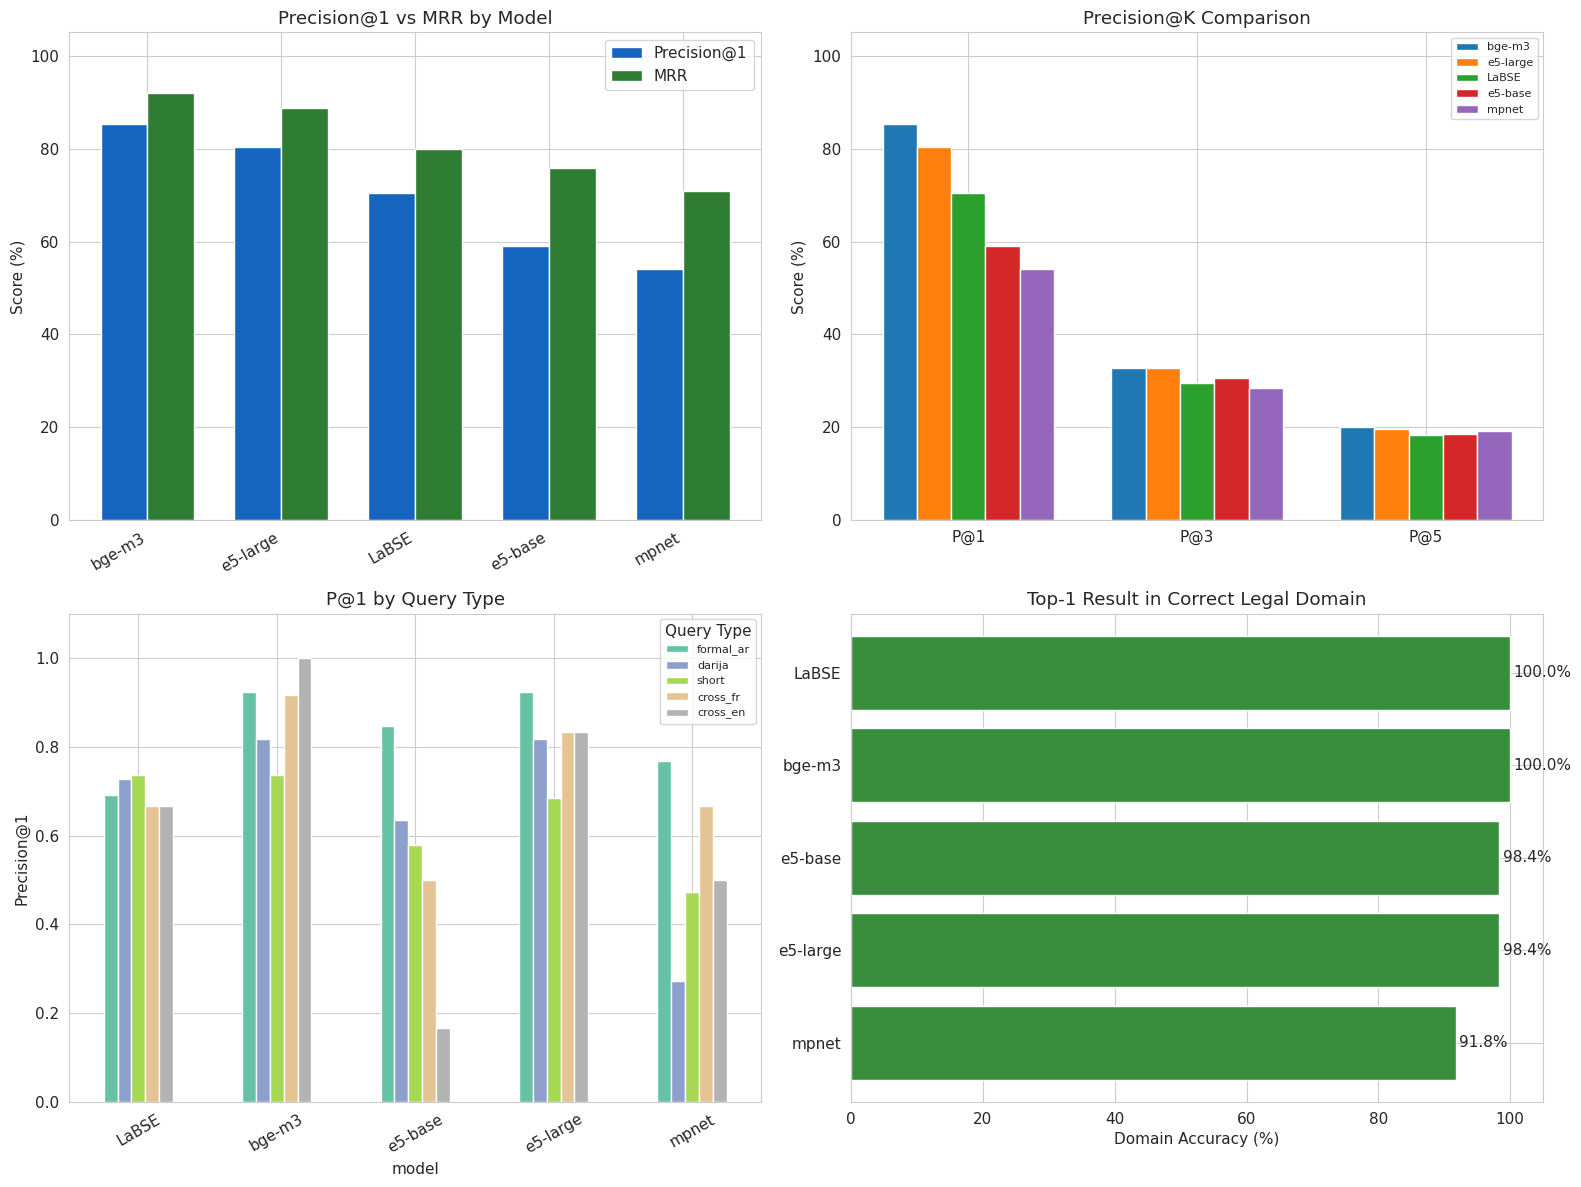

In [7]:
sns.set_style("whitegrid")
plt.rcParams.update({'font.size': 11})

# === FIGURE 1: Overall Performance Comparison ===
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1a: Bar chart - P@1 and MRR per model
ax = axes[0, 0]
x = np.arange(len(overall))
width = 0.35
ax.bar(x - width/2, overall["p1"]*100, width, label="Precision@1", color="#1565C0")
ax.bar(x + width/2, overall["mrr"]*100, width, label="MRR", color="#2E7D32")
ax.set_xticks(x)
ax.set_xticklabels(overall.index, rotation=30, ha="right")
ax.set_ylabel("Score (%)")
ax.set_title("Precision@1 vs MRR by Model")
ax.legend()
ax.set_ylim(0, 105)

# 1b: Radar-like grouped bar - P@1, P@3, P@5
ax = axes[0, 1]
metrics = ["p1", "p3", "p5"]
x = np.arange(len(metrics))
width = 0.15
for i, (model_name, row) in enumerate(overall.iterrows()):
    values = [row[m]*100 for m in metrics]
    ax.bar(x + i*width, values, width, label=model_name)
ax.set_xticks(x + width*2)
ax.set_xticklabels(["P@1", "P@3", "P@5"])
ax.set_ylabel("Score (%)")
ax.set_title("Precision@K Comparison")
ax.legend(fontsize=8)
ax.set_ylim(0, 105)

# 1c: Query type breakdown
ax = axes[1, 0]
pivot = by_type.pivot_table(values="p1", index="model", columns="q_type", aggfunc="mean")
pivot = pivot[["formal_ar", "darija", "short", "cross_fr", "cross_en"]]
pivot.plot(kind="bar", ax=ax, colormap="Set2")
ax.set_ylabel("Precision@1")
ax.set_title("P@1 by Query Type")
ax.legend(title="Query Type", fontsize=8)
ax.tick_params(axis="x", rotation=30)
ax.set_ylim(0, 1.1)

# 1d: Domain accuracy (is top result in correct domain?)
ax = axes[1, 1]
domain_acc = overall["domain_acc"].sort_values(ascending=True)
colors = ["#D32F2F" if v < 0.8 else "#388E3C" if v > 0.9 else "#FBC02D" for v in domain_acc.values]
ax.barh(range(len(domain_acc)), domain_acc.values*100, color=colors)
ax.set_yticks(range(len(domain_acc)))
ax.set_yticklabels(domain_acc.index)
ax.set_xlabel("Domain Accuracy (%)")
ax.set_title("Top-1 Result in Correct Legal Domain")
for i, v in enumerate(domain_acc.values):
    ax.text(v*100 + 0.5, i, f"{v*100:.1f}%", va="center")
ax.set_xlim(0, 105)

plt.tight_layout()
plt.show()

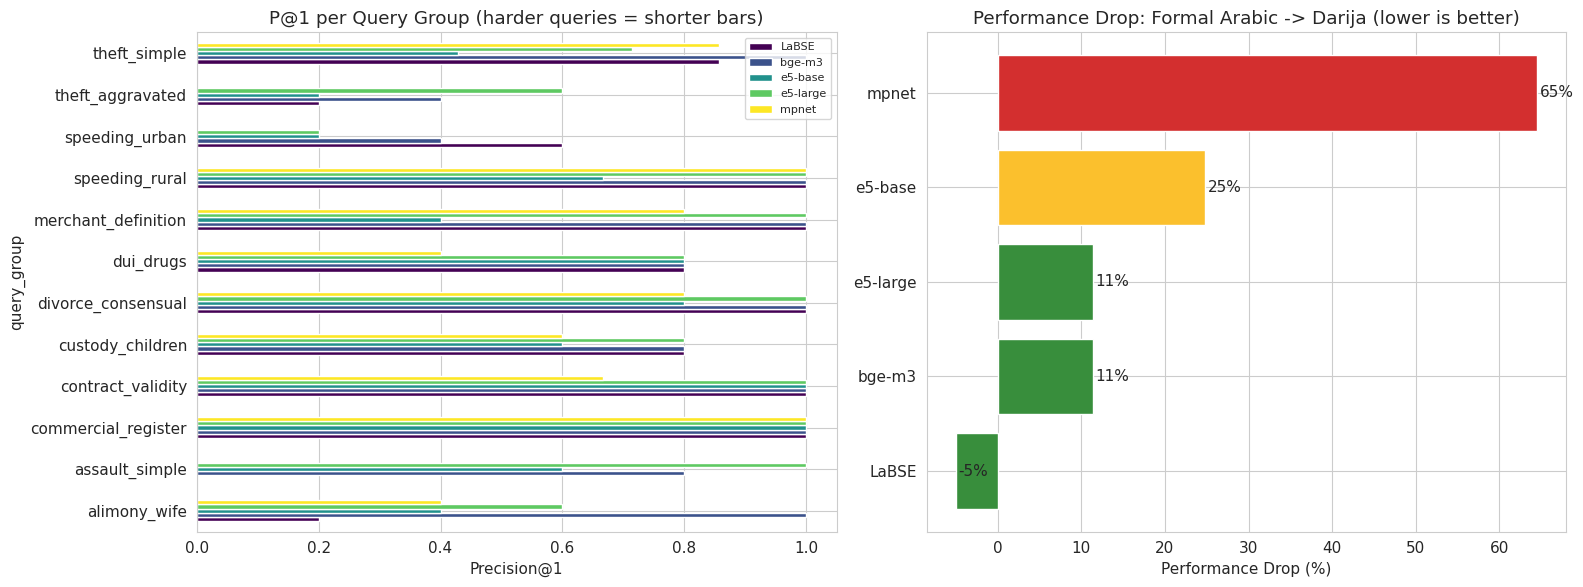

In [8]:
# === FIGURE 2: Query Difficulty ===
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 2a: Per-query-group P@1 (shows which queries are hardest)
ax = axes[0]
query_difficulty = results_df.groupby(["query_group", "model"])["p1"].mean().reset_index()
pivot_diff = query_difficulty.pivot_table(values="p1", index="query_group", columns="model")
pivot_diff.plot(kind="barh", ax=ax, colormap="viridis")
ax.set_xlabel("Precision@1")
ax.set_title("P@1 per Query Group (harder queries = shorter bars)")
ax.legend(fontsize=8)
ax.set_xlim(0, 1.05)

# 2b: Performance drop-off: formal vs darija
ax = axes[1]
formal = results_df[results_df["q_type"] == "formal_ar"].groupby("model")["p1"].mean()
darija = results_df[results_df["q_type"] == "darija"].groupby("model")["p1"].mean()
dropoff = ((formal - darija) / formal * 100).sort_values()
colors = ["#D32F2F" if v > 30 else "#FBC02D" if v > 15 else "#388E3C" for v in dropoff.values]
ax.barh(range(len(dropoff)), dropoff.values, color=colors)
ax.set_yticks(range(len(dropoff)))
ax.set_yticklabels(dropoff.index)
ax.set_xlabel("Performance Drop (%)")
ax.set_title("Performance Drop: Formal Arabic -> Darija (lower is better)")
for i, v in enumerate(dropoff.values):
    ax.text(v + 0.3, i, f"{v:.0f}%", va="center")

plt.tight_layout()
plt.show()

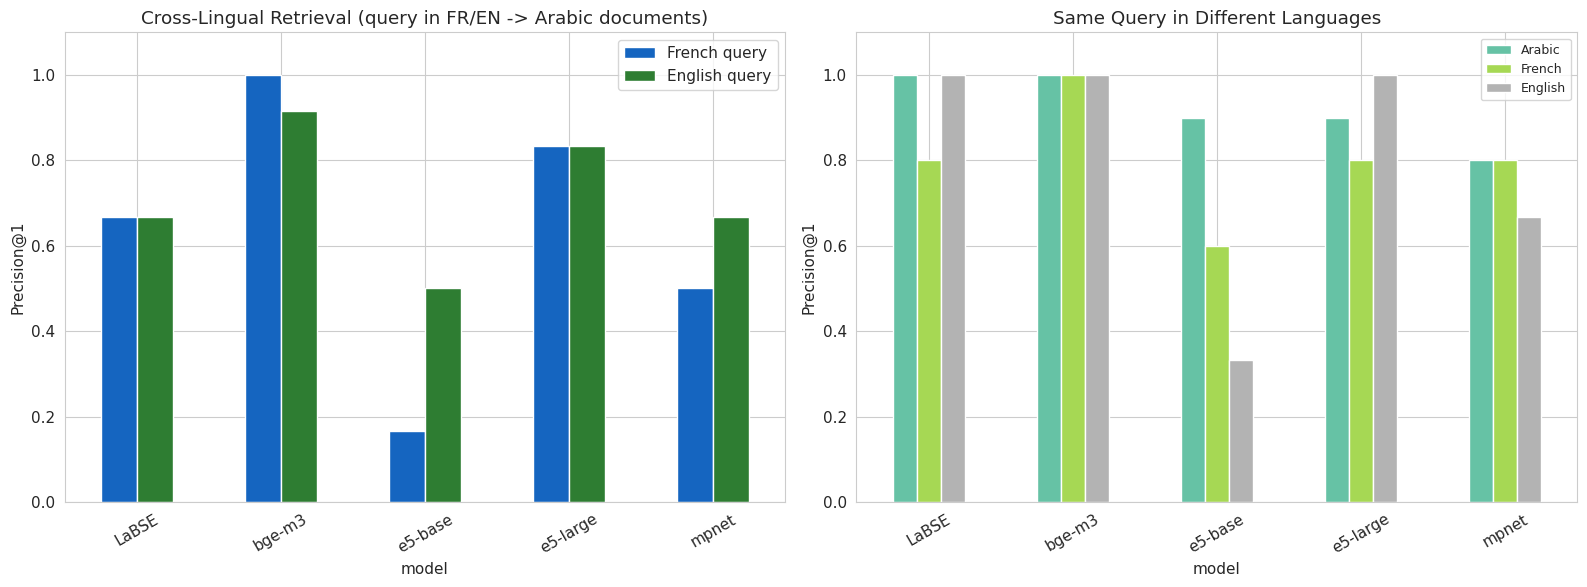

In [9]:
# === FIGURE 3: Cross-lingual capability ===
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 3a: Cross-lingual P@1 (French query -> Arabic docs, etc.)
ax = axes[0]
cross = results_df[results_df["q_type"].isin(["cross_fr", "cross_en"])]
cross_pivot = cross.groupby(["model", "q_type"])["p1"].mean().reset_index()
cross_pivot = cross_pivot.pivot_table(values="p1", index="model", columns="q_type")
cross_pivot.columns = ["French query", "English query"]
cross_pivot.plot(kind="bar", ax=ax, color=["#1565C0", "#2E7D32"])
ax.set_ylabel("Precision@1")
ax.set_title("Cross-Lingual Retrieval (query in FR/EN -> Arabic documents)")
ax.legend()
ax.tick_params(axis="x", rotation=30)
ax.set_ylim(0, 1.1)

# 3b: Comparison: same query in different languages
ax = axes[1]
sample_queries = ["theft_simple", "divorce_consensual", "contract_validity"]
lang_data = []
for qg in sample_queries:
    subset = results_df[results_df["query_group"] == qg]
    for _, row in subset.iterrows():
        lang_data.append({
            "model": row["model"],
            "query": qg,
            "language": row["variant"].split("_")[0],
            "p1": row["p1"],
        })
lang_df = pd.DataFrame(lang_data)
# Pivot: average across the sample queries per model and language
pivot_lang = lang_df.pivot_table(values="p1", index="model", columns="language", aggfunc="mean")
pivot_lang = pivot_lang[["ar", "fr", "en"]] if all(c in pivot_lang.columns for c in ["ar", "fr", "en"]) else pivot_lang
pivot_lang.plot(kind="bar", ax=ax, colormap="Set2")
ax.set_ylabel("Precision@1")
ax.set_title("Same Query in Different Languages")
ax.legend(["Arabic", "French", "English"], fontsize=9)
ax.tick_params(axis="x", rotation=30)
ax.set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

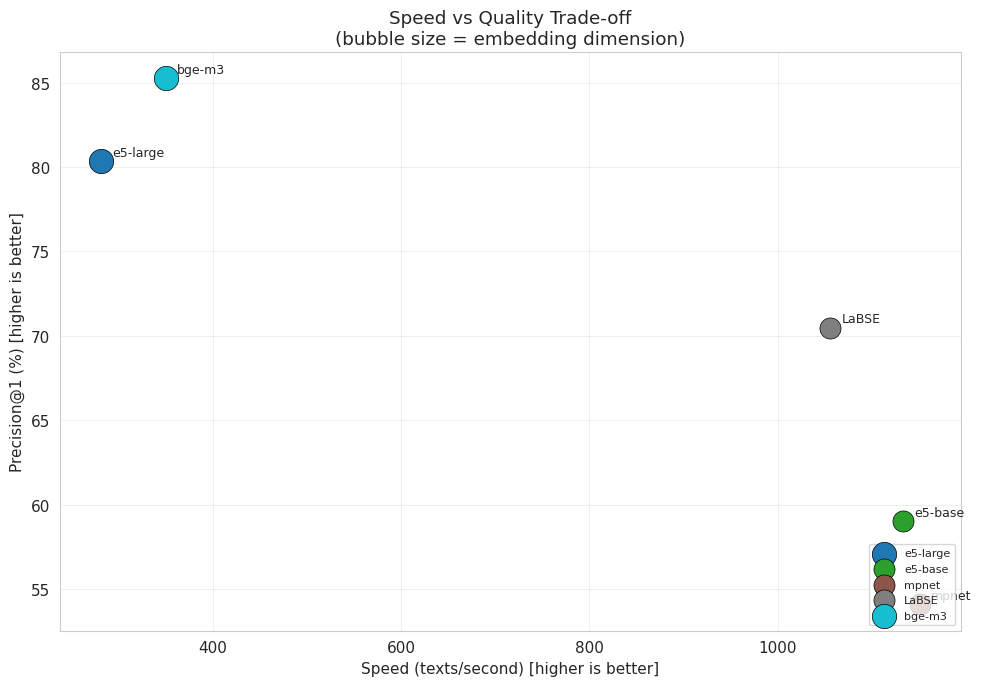

In [11]:
# === FIGURE 4: Speed vs Quality ===
fig, ax = plt.subplots(figsize=(10, 7))

# Benchmark speed
test_texts = [f"المادة {i} من القانون: نص قانوني للاختبار رقم {i}." for i in range(200)]
speed_data = {}

for model_name, info in model_cache.items():
    if info is None:
        continue
    model = info["model"]
    _ = model.encode(test_texts[:5], normalize_embeddings=True)
    start = time.time()
    _ = model.encode(test_texts, normalize_embeddings=True, batch_size=32)
    elapsed = time.time() - start
    speed_data[model_name] = {"texts_per_sec": 200/elapsed, "dim": info["dim"], "p1": overall.loc[model_name, "p1"]}

speed_df = pd.DataFrame(speed_data).T

# Scatter: x = speed, y = P@1, size = dimension, color = model
colors = plt.cm.tab10(np.linspace(0, 1, len(speed_df)))
for i, (model_name, row) in enumerate(speed_df.iterrows()):
    ax.scatter(row["texts_per_sec"], row["p1"]*100, s=row["dim"]*0.3,
              color=colors[i], label=model_name, edgecolors="black", linewidth=0.5)
    ax.annotate(model_name, (row["texts_per_sec"], row["p1"]*100),
               textcoords="offset points", xytext=(8, 4), fontsize=9)

ax.set_xlabel("Speed (texts/second) [higher is better]")
ax.set_ylabel("Precision@1 (%) [higher is better]")
ax.set_title("Speed vs Quality Trade-off\n(bubble size = embedding dimension)")
ax.legend(fontsize=8, loc="lower right")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
# Pairwise comparison: which model pairs have statistically different P@1?
from scipy.stats import ttest_rel

print("=" * 90)
print("PAIRWISE T-TEST: Is the difference statistically significant?")
print("=" * 90)
print("p < 0.05 = significant difference")
print()

models_list = [m for m in model_cache if model_cache[m] is not None]
pivot_model = results_df.pivot_table(
    values="p1", index=["query_group", "variant"], columns="model", aggfunc="first"
).dropna()

for i, m1 in enumerate(models_list):
    for m2 in models_list[i+1:]:
        t_stat, p_val = ttest_rel(pivot_model[m1], pivot_model[m2])
        sig = "SIGNIFICANT" if p_val < 0.05 else "not significant"
        print(f"  {m1} vs {m2}: p={p_val:.4f} ({sig})")

PAIRWISE T-TEST: Is the difference statistically significant?
p < 0.05 = significant difference

  e5-large vs e5-base: p=0.0002 (SIGNIFICANT)
  e5-large vs mpnet: p=0.0002 (SIGNIFICANT)
  e5-large vs LaBSE: p=0.1590 (not significant)
  e5-large vs bge-m3: p=0.3213 (not significant)
  e5-base vs mpnet: p=0.5172 (not significant)
  e5-base vs LaBSE: p=0.1277 (not significant)
  e5-base vs bge-m3: p=0.0002 (SIGNIFICANT)
  mpnet vs LaBSE: p=0.0065 (SIGNIFICANT)
  mpnet vs bge-m3: p=0.0000 (SIGNIFICANT)
  LaBSE vs bge-m3: p=0.0188 (SIGNIFICANT)


In [13]:
# ============================================
# FINAL RECOMMENDATION
# ============================================

best_model = overall.index[0]
best_p1 = overall.iloc[0]["p1"] * 100
best_mrr = overall.iloc[0]["mrr"] * 100
best_domain = overall.iloc[0]["domain_acc"] * 100
best_dim = model_cache[best_model]["dim"]

darija_p1 = results_df[(results_df["model"] == best_model) & (results_df["q_type"] == "darija")]["p1"].mean() * 100
crossfr_p1 = results_df[(results_df["model"] == best_model) & (results_df["q_type"] == "cross_fr")]["p1"].mean() * 100

# Runner-up
runner_up = overall.index[1]
ru_p1 = overall.iloc[1]["p1"] * 100

print("=" * 80)
print("RECOMMENDED MODEL")
print("=" * 80)
print(f"""
Model: {best_model}
  Embedding dimension: {best_dim}
  Precision@1: {best_p1:.1f}%
  MRR: {best_mrr:.1f}%
  Domain accuracy: {best_domain:.1f}%
  Darija handling: {darija_p1:.1f}%
  French cross-lingual: {crossfr_p1:.1f}%

Runner-up: {runner_up} (P@1: {ru_p1:.1f}%)

""")

# Actionable config line
print("Add to config.yaml:")
print(f"  embedding_model: {MODELS[best_model]}")
print()
print("Re-index with new model:")
print(f"  python scripts/seed_test_data.py --clear --model {best_model}")

RECOMMENDED MODEL

Model: bge-m3
  Embedding dimension: 1024
  Precision@1: 85.2%
  MRR: 91.9%
  Domain accuracy: 100.0%
  Darija handling: 81.8%
  French cross-lingual: 91.7%

Runner-up: e5-large (P@1: 80.3%)


Add to config.yaml:
  embedding_model: BAAI/bge-m3

Re-index with new model:
  python scripts/seed_test_data.py --clear --model bge-m3
